In [1]:
from google.colab import drive
drive.mount('/content/drive')
#calea pentru a putea incarca din drive datele
#are o dimensiune prea mare pentru a le putea incarca in mod normal
file_path='/content/drive/MyDrive/Colab Notebooks/PI-P/video_calciu_1.tif'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Bibliotecile au fost importate cu succes!
Total cadre in fisier: 6000
Dimensiunea cadrelor: (512, 512)
Dimensiunea datelor încărcate efectiv în RAM: (500, 512, 512)
Valoarea maximă inițială a fost 32563.0, datele au fost normalizate între [0, 1].


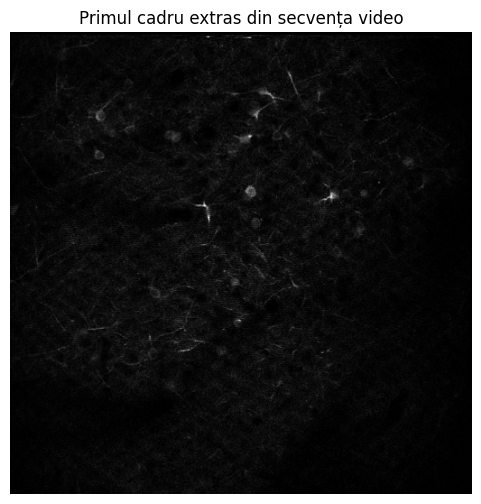

Număr cadre pentru antrenament (Ground Truth): 400
Număr cadre pentru testare: 100


In [5]:
!pip install -q tifffile scikit-image opencv-python

import numpy as np
import tifffile
import matplotlib.pyplot as plt
import os
print("Bibliotecile au fost importate cu succes!")

file_path = '/content/drive/MyDrive/Colab Notebooks/PI-P/video_calciu_1.tif'

if not os.path.exists(file_path):
  print(f"Eroare: Nu găsesc fișierul la calea: {file_path}")
else:
  #nu exista suficient RAM pentru a incarca tot setul de date
  #trebuie sa fie incarcat pe bucati
  #memory mapping - o legatura virtuala cu fisierele de pe disc, le incarca doar cand este necesar
  video_memmap = tifffile.memmap(file_path)
  total_frames, height, width = video_memmap.shape
  print(f"Total cadre in fisier: {total_frames}")
  print(f"Dimensiunea cadrelor: {height,width}")

  #se aleg primele 500 de cadre pentru procesare
  max_cadre = 500
  video_subset = video_memmap[:max_cadre]
  #copierea datelor in memoria RAM cu precizie float32
  video_data = np.array(video_subset, dtype=np.float32)
  print(f"Dimensiunea datelor încărcate efectiv în RAM: {video_data.shape}")

  #pentru a eficientiza invatarea se face o normalizare intre [0,1]
  #se verifica care este valoarea maxima a pixelilor(cea mai mare intensitate luminoasa)
  max_val = np.max(video_data)

  if max_val > 0:
    video_normalizat = video_data.astype(np.float32) / max_val
  else:
    video_normalizat = video_data.astype(np.float32)
  print(f"Valoarea maximă inițială a fost {max_val}, datele au fost normalizate între [0, 1].")

  #afisarea ferestrei
  plt.figure(figsize=(6, 6))
  plt.imshow(video_normalizat[0], cmap='gray')
  plt.title("Primul cadru extras din secvența video")
  plt.axis('off')
  plt.show()

  split_index = int(len(video_normalizat) * 0.8)

  y_train = video_normalizat[:split_index]
  y_test = video_normalizat[split_index:]

  print(f"Număr cadre pentru antrenament (Ground Truth): {len(y_train)}")
  print(f"Număr cadre pentru testare: {len(y_test)}")

In [15]:
!git rm --cached calcium-image-denoising
!rm -rf calcium-image-denoising/.git
!git add calcium-image-denoising/
!git commit -m "Corectat: Am adaugat incarcarea imaginilor in google colab si normalizarea acestora"
!git push origin main

fatal: pathspec 'calcium-image-denoising' did not match any files
[main fa38acb] Corectat: Am adaugat incarcarea imaginilor in google colab si normalizarea acestora
 3 files changed, 37 insertions(+), 1 deletion(-)
 delete mode 160000 calcium-image-denoising
 create mode 100644 calcium-image-denoising/README.md
 create mode 100644 calcium-image-denoising/docs/schema_bloc.png
Enumerating objects: 4, done.
Counting objects: 100% (4/4), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 439 bytes | 439.00 KiB/s, done.
Total 3 (delta 0), reused 1 (delta 0), pack-reused 0
To https://github.com/vlad-budeanu/calcium-image-denoising.git
   ec75458..fa38acb  main -> main
